# What can this dataset support?

A feasibility audit of the Global Sales Dataset (100,000 orders, 2015-2024). Before building
any model, this notebook asks four questions: can monthly revenue be forecast, can order
revenue be predicted, do customers form natural segments, and is the data real?

> **TL;DR**
> - **Forecasting refused.** None of 7 alternatives beats the historical mean of 1.10 M USD
>   per month; the best, `linear_trend`, is 0.6 % worse.
> - **High order R² is leakage or price tier.** `leaky` reaches R² 0.999 (quantity x price);
>   honest features reach 0.35, all from product; without product, R² is 0.
> - **The data appears synthetic.** Revenue equals quantity x price on 99.999 % of rows,
>   product margins are flat (sd 0.18 pp), and 25,726 customers change segment between orders.
> - **No natural customer clusters.** K-Means silhouette peaks at 0.38 (k=2) against nulls of
>   0.32 and 0.26, and falls to the null level at k=5. Quantile RFM is kept
>   (ARI with K-Means 0.31).

*Glossary.* **Leakage**: a feature that is only known after the target happens, or is computed
from it. **TimeSeriesSplit** (rolling-origin): folds where the model only sees the past.
**RFM**: Recency, Frequency, Monetary. **Silhouette**: how well a point fits its own cluster
against the nearest other one (-1 to 1). **ARI**: adjusted Rand index, agreement between two
partitions (1 = identical, about 0 = chance).

All computations live in `src/retail_sales_pipeline/audit.py` and `segmentation.py`. Figures
are also saved to `reports/figures/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from sklearn.cluster import KMeans
from statsmodels.graphics.tsaplots import plot_acf

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "retail_sales_pipeline").is_dir())
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
DPI = 120

from retail_sales_pipeline import audit, segmentation as sg, transform
from retail_sales_pipeline.config import RAW_CSV

def save(fig, name):
    fig.savefig(FIG / name, dpi=DPI, bbox_inches="tight")
    return fig

## 1. Data: is this real transactional data?

**Question / hypothesis.** The dataset claims to record real orders. Real retail data usually
shows noise: margins that vary by product, revenue that is not an exact product of its columns,
and customer attributes that stay stable. If those signs are missing, every later result is
about the generator, not about retail.

**Protocol.** Load the raw CSV (schema inferred on 100,000 rows, as in the pipeline), clean it
with `transform.clean`, then run `audit.synthetic_fingerprints` on the raw frame.

**Results.** The table lists the fingerprints. The verdict is printed below it.

In [2]:
raw = pl.read_csv(RAW_CSV, infer_schema_length=100_000)
clean = transform.clean(raw)
print(f"raw: {raw.height:,} rows x {raw.width} columns | "
      f"clean: {clean.height:,} rows x {clean.width} columns")

fp = audit.synthetic_fingerprints(raw)
keys = [k for k in fp if k != "verdict"]
pl.DataFrame({"fingerprint": keys, "value": [float(fp[k]) for k in keys]})

raw: 100,000 rows x 50 columns | clean: 100,000 rows x 55 columns


fingerprint,value
str,f64
"""n_rows""",100000.0
"""null_count_total""",0.0
"""duplicate_rows""",0.0
"""revenue_identity_share""",0.99999
"""product_margin_sd_pp""",0.181
"""month_of_year_revenue_cv""",0.032612
"""customers_multi_order""",29636.0
"""customers_segment_conflict""",25726.0
"""customers_churn_prob_conflict""",29177.0


In [3]:
print(fp["verdict"])

synthetic-looking: revenue_usd = quantity x unit_price_after_discount_usd on almost every row; profit margin flat across products (sd 0.18 pp); customer_segment changes between orders of the same customer


**Interpretation.** This dataset appears synthetic. `revenue_usd` equals
`quantity x unit_price_after_discount_usd` on 99.999 % of rows. Profit margin is flat across
products (standard deviation 0.18 points). Monthly revenue barely moves (coefficient of
variation 3 %). About 25,700 customers have more than one `customer_segment` across their
orders, which a real CRM would not produce. Read every result below as a property of this
generator.
which a real CRM would not produce. Read every result below as a property of this generator.

**Conclusion.** Treat the data as a teaching or engineering fixture. The findings do not
transfer to real retail without a real dataset.

## 2. Can we forecast monthly revenue?

**Question / hypothesis.** Revenue has a visible seasonal pattern in STL decomposition. Does
any forecaster beat a trivial "predict the historical mean" baseline on data it has not seen?

**Protocol.** Realised revenue per calendar month (`audit.monthly_series`, 120 months, gaps
counted as zero). Diagnostics via `audit.forecastability`: coefficient of variation,
autocorrelation, Ljung-Box white-noise test, STL strengths. Then `audit.backtest_forecasters`:
five rolling-origin folds, 12-month horizon, every model fitted on the training part of each
fold only.
Scored with `audit.summarise_backtest` on MAE, relative to the mean forecast.

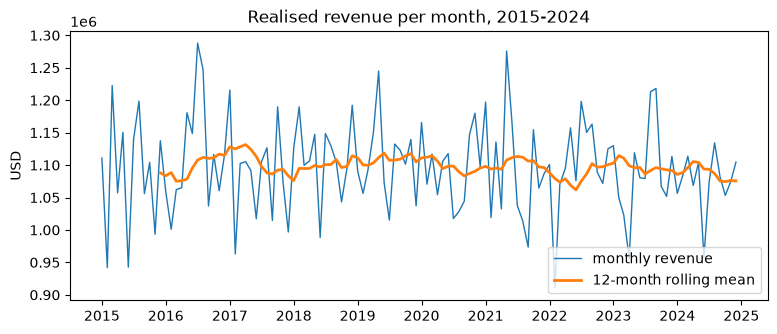

Historical mean monthly revenue: 1,096,478 USD


In [4]:
monthly = audit.monthly_series(clean)
y = monthly["revenue_usd"].to_numpy()
months = monthly["month_start"].to_list()
roll = monthly["revenue_usd"].rolling_mean(12).to_list()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(months, y, lw=1, label="monthly revenue")
ax.plot(months, roll, lw=2, label="12-month rolling mean")
ax.set_ylabel("USD")
ax.set_title("Realised revenue per month, 2015-2024")
ax.legend(loc="lower right")
save(fig, "monthly_revenue.png")
plt.show()
print(f"Historical mean monthly revenue: {y.mean():,.0f} USD")

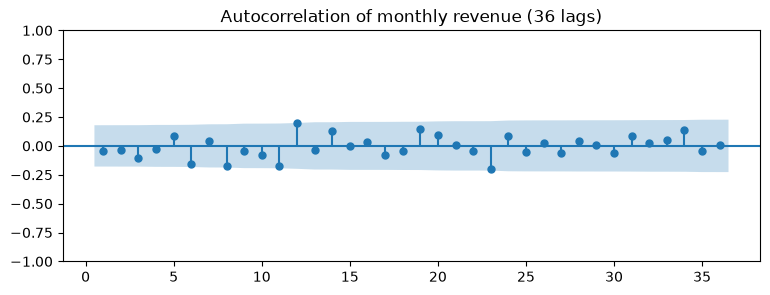

In [5]:
fig, ax = plt.subplots(figsize=(9, 3))
plot_acf(y, lags=36, ax=ax, zero=False)
ax.set_title("Autocorrelation of monthly revenue (36 lags)")
save(fig, "acf.png")
plt.show()

In [6]:
fa = audit.forecastability(y)
flat = {
    "n_months": fa["n_months"],
    "cv": round(fa["cv"], 4),
    **{f"acf_{k}": round(v, 4) for k, v in fa["acf"].items()},
    "ljung_box_p_12": round(fa["ljung_box_p_12"], 4),
    "ljung_box_p_24": round(fa["ljung_box_p_24"], 4),
    "seasonal_strength (STL, in-sample)": round(fa["seasonal_strength"], 4),
    "trend_strength (STL, in-sample)": round(fa["trend_strength"], 4),
    "is_white_noise (alpha 0.05)": fa["is_white_noise"],
}
pl.DataFrame({"metric": list(flat), "value": [str(v) for v in flat.values()]})

metric,value
str,str
"""n_months""","""120"""
"""cv""","""0.0644"""
"""acf_lag1""","""-0.0422"""
"""acf_lag12""","""0.1972"""
"""acf_lag24""","""0.0814"""
"""ljung_box_p_12""","""0.0608"""
"""ljung_box_p_24""","""0.0565"""
"""seasonal_strength (STL, in-sam…","""0.5526"""
"""trend_strength (STL, in-sample…","""0.1337"""


In [7]:
bt = audit.backtest_forecasters(y, n_splits=5, test_size=12, start_month=1)
summary = audit.summarise_backtest(bt)
summary.select("model", "mae_mean", "mae_std", "mape_mean", "skill_vs_mean_pct")

model,mae_mean,mae_std,mape_mean,skill_vs_mean_pct
str,f64,f64,f64,f64
"""mean""",51493.822519,15641.014761,4.78429,1.1102e-14
"""linear_trend""",51794.774147,15937.104463,4.824216,-0.584442
"""rolling_mean_3""",52065.307111,20046.610591,4.8664,-1.109812
"""holt_winters""",57937.555616,12673.115077,5.414937,-12.513604
"""naive""",58704.026667,12971.133946,5.418407,-14.002076
"""drift""",59945.379784,13357.088806,5.526399,-16.41276
"""seasonal_naive""",63999.850667,17793.096191,5.873465,-24.286463
"""gbr_lags""",66138.044939,14012.927765,6.089626,-28.438795


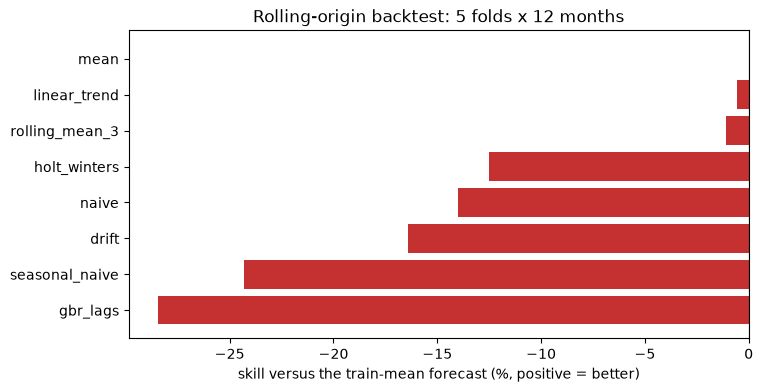

In [8]:
s = summary.sort("skill_vs_mean_pct")
colors = ["#2b6cb0" if v >= 0 else "#c53030" for v in s["skill_vs_mean_pct"].to_list()]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(s["model"].to_list(), s["skill_vs_mean_pct"].to_list(), color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("skill versus the train-mean forecast (%, positive = better)")
ax.set_title("Rolling-origin backtest: 5 folds x 12 months")
save(fig, "backtest_skill.png")
plt.show()

**Interpretation.** No model beats the mean. The best is `linear_trend` at -0.6 %, which is
within noise of zero. `holt_winters` is 12.5 % worse and `gbr_lags` 28 % worse. Ljung-Box gives
p around 0.06, which is borderline white noise. STL finds a seasonal strength of about 0.55
in-sample, but seasonal models lose out of sample, so the seasonality does not carry forward.

**Conclusion.** Forecasting is refused. The historical mean is the honest forecast, and any
forecast with a trend or seasonal shape would be less accurate on this data.

## 3. Can we predict order revenue?

**Question / hypothesis.** Order revenue is almost a function of quantity and price. How
much of it can be explained by information that is actually available before the order is
placed, and how much comes from leakage?

**Protocol.** `audit.leakage_demo` predicts `revenue_usd` per realised order under five feature
sets, with a chronological split (train before 2023-01-01, test 2023-2024). Feature sets:
`leaky` (quantity, unit price, discount), `derived_customer` (customer snapshot columns computed
from the orders), `honest` (product, country, channel, segment, and so on), `honest_no_product`
(the same without product), and a mean baseline. `audit.derived_column_check` tests whether the
customer snapshot columns are computed from the orders.

In [9]:
ld = audit.leakage_demo(clean)
ld.select("feature_set", "model", "r2", "mae", "n_train", "n_test")

feature_set,model,r2,mae,n_train,n_test
str,str,f64,f64,i64,i64
"""none""","""mean""",-0.000064,1252.682356,62520,15534
"""leaky""","""ridge""",0.803185,501.856777,62520,15534
"""leaky""","""hist_gbr""",0.99862,19.64666,62520,15534
"""derived_customer""","""ridge""",0.496497,786.504222,62520,15534
"""derived_customer""","""hist_gbr""",0.469305,792.39299,62520,15534
"""honest""","""ridge""",0.356189,912.952624,62520,15534
"""honest""","""hist_gbr""",0.353364,913.87842,62520,15534
"""honest_no_product""","""ridge""",-0.000641,1253.048506,62520,15534
"""honest_no_product""","""hist_gbr""",-0.00055,1254.424839,62520,15534


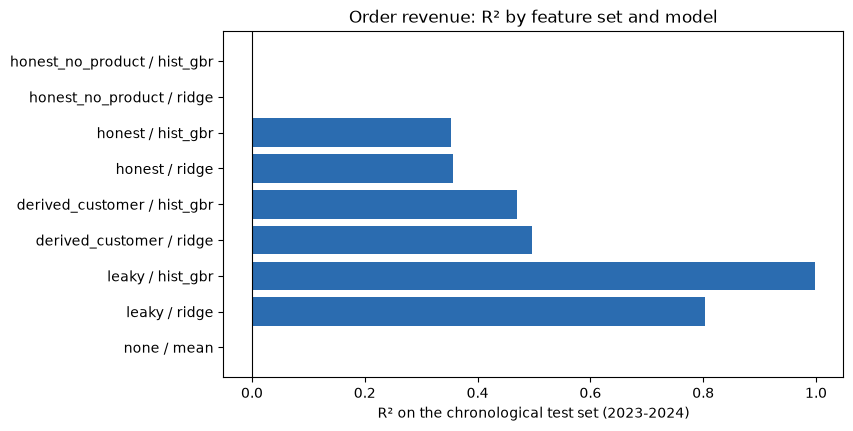

In [10]:
lab = [f"{f} / {m}" for f, m in zip(ld["feature_set"].to_list(), ld["model"].to_list())]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(lab, ld["r2"].to_list(), color="#2b6cb0")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("R² on the chronological test set (2023-2024)")
ax.set_title("Order revenue: R² by feature set and model")
save(fig, "leakage_r2.png")
plt.show()

In [11]:
dcc = audit.derived_column_check(clean)
dcc

column,pearson_row,spearman_row,customer_actual,pearson_customer,spearman_customer
str,f64,f64,str,f64,f64
"""monetary_total_usd""",0.425506,0.405664,"""sum_realised_revenue_usd""",0.974186,0.91946
"""avg_order_value_usd""",0.591518,0.551486,"""sum_realised_revenue_usd""",0.639606,0.724423
"""clv_3yr_usd""",0.206065,0.406212,"""sum_realised_revenue_usd""",0.198671,0.687039
"""engagement_score""",0.246669,0.235053,"""sum_realised_revenue_usd""",0.8357,0.876547
"""rfm_total_score""",0.20531,0.207815,"""sum_realised_revenue_usd""",0.711713,0.734686
"""rfm_m_score""",0.391225,0.391761,"""sum_realised_revenue_usd""",0.858355,0.899738
"""frequency_orders""",0.000505,-0.000468,"""order_count""",0.857203,0.832863


**Interpretation.** `leaky` reaches R² 0.999 with gradient boosting. This is not a model, it is
the revenue formula: revenue is quantity times price, and both inputs are in the feature set.
`derived_customer` reaches about 0.47-0.50. Its columns (monetary total, CLV, RFM score) are
computed from the same orders, so they carry the target. The `honest` set reaches about
0.35, and
all of it comes from `product`: each product has its own price band (Product_E about 60-98 USD,
Product_D about 800-1,300 USD), so product acts as a price tier. Without product, the honest set
explains nothing (R² around 0).

The derived-column check confirms that the customer snapshot columns are computed from the
orders.
Customer-level correlations with the actual realised total are high (monetary total 0.97, RFM
monetary score 0.86), while row-level correlations are weak.

**Conclusion.** Any good R² here comes from leakage or from the price tier. There is no demand
signal beyond what the price list already implies.

## 4. Do customers form natural segments?

**Question / hypothesis.** Are there distinct groups of customers in recency, frequency and
monetary value, or does the data form one continuum that clustering only cuts up?

**Protocol.** RFM is recomputed from realised orders only (`sg.compute_rfm`), then
standardised with `sg.rfm_features`. K-Means runs for k = 2 to 6 (`sg.evaluate_k`, silhouette
estimated on 10,000 rows). For k = 2, 3, 5, `sg.stability` compares runs on subsamples and
seeds, and `sg.null_baseline` compares the silhouette with two structure-free references
(uniform in the bounding box, and column-wise permutation). Finally, the k = 2 clusters are
profiled and compared with the classic rule-based RFM segments (`sg.rfm_quantile_segments`)
using the adjusted Rand index.

In [12]:
rfm = sg.compute_rfm(clean)
freq = rfm["frequency"]
print(f"{rfm.height:,} customers with at least one realised order")
print(f"mean realised orders per customer: {freq.mean():.2f} | "
      f"single-order share: {(freq == 1).mean():.1%}")
freq.value_counts().sort("frequency")

39,480 customers with at least one realised order
mean realised orders per customer: 1.98 | single-order share: 41.6%


frequency,count
u32,u32
1,16437
2,12680
3,6633
4,2646
5,800
6,228
7,43
8,12
9,1


In [13]:
X, scaler = sg.rfm_features(rfm)
ek = sg.evaluate_k(X, k_range=range(2, 7))
ek

k,inertia,silhouette,davies_bouldin,calinski_harabasz
i64,f64,f64,f64,f64
2,66981.223888,0.377035,1.061042,30329.270941
3,50539.984482,0.342882,1.108847,26518.790255
4,41493.862234,0.299619,1.112079,24402.00385
5,34638.151337,0.299087,1.065302,23876.337879
6,29916.735586,0.313301,1.015681,23360.950121


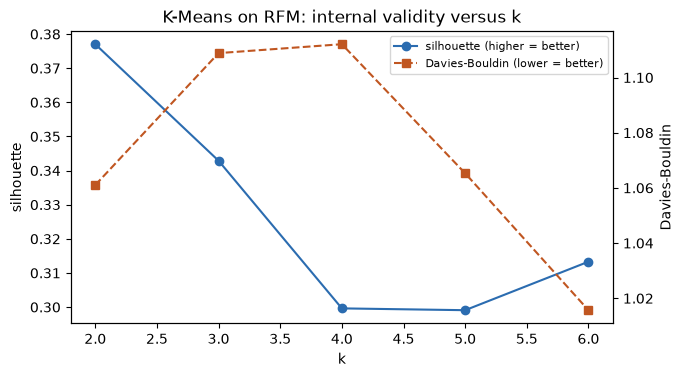

In [14]:
fig, ax1 = plt.subplots(figsize=(7, 3.8))
ax1.plot(ek["k"].to_list(), ek["silhouette"].to_list(), "o-", color="#2b6cb0",
         label="silhouette (higher = better)")
ax1.set_xlabel("k")
ax1.set_ylabel("silhouette")
ax2 = ax1.twinx()
ax2.plot(ek["k"].to_list(), ek["davies_bouldin"].to_list(), "s--", color="#c05621",
         label="Davies-Bouldin (lower = better)")
ax2.set_ylabel("Davies-Bouldin")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8)
ax1.set_title("K-Means on RFM: internal validity versus k")
save(fig, "kmeans_k.png")
plt.show()

In [15]:
rows = []
for k in (2, 3, 5):
    st = sg.stability(X, k, n_runs=5)
    nb = sg.null_baseline(X, k)
    rows.append({
        "k": k,
        "silhouette_real": nb["real_silhouette"],
        "silhouette_uniform_null": nb["uniform_silhouette"],
        "silhouette_permuted_null": nb["permuted_silhouette"],
        "ari_subsample_mean": st["subsample_ari_mean"],
        "ari_seed_mean": st["seed_ari_mean"],
    })
robustness = pl.DataFrame(rows)
robustness

k,silhouette_real,silhouette_uniform_null,silhouette_permuted_null,ari_subsample_mean,ari_seed_mean
i64,f64,f64,f64,f64,f64
2,0.377035,0.321271,0.260537,0.988836,0.993994
3,0.342882,0.296429,0.278327,0.974929,0.986397
5,0.299087,0.278304,0.293416,0.969816,0.980317


In [16]:
# Same settings as sg.evaluate_k (n_init=10, random_state=42), so the labels match the
# table above.
labels_k2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X)
sg.profile_clusters(rfm, labels_k2)

cluster,name,size,share_pct,median_recency_days,median_frequency,median_monetary_usd,mean_monetary_usd
i64,str,u32,f64,f64,f64,f64,f64
0,"""Lapsed low-value""",18955,48.011651,1950.0,1.0,1070.42,1524.090754
1,"""Recent high-value""",20525,51.988349,721.0,3.0,4194.89,5003.081531


In [17]:
q = sg.rfm_quantile_segments(rfm)
assert q["customer_id"].to_list() == rfm["customer_id"].to_list()
print(q.group_by("segment").agg(pl.len().alias("customers")).sort("customers", descending=True))
print(q.group_by("segment").agg(
    pl.col("recency_days").median().alias("median_recency_days"),
    pl.col("frequency").median().alias("median_frequency"),
    pl.col("monetary").median().alias("median_monetary_usd"),
).sort("median_monetary_usd", descending=True))
cmp = sg.compare_segmentations(labels_k2, q["segment"].to_list())
print(f"ARI between K-Means (k=2) and quantile RFM segments: {cmp['ari']:.2f}")

shape: (6, 2)
┌────────────────────┬───────────┐
│ segment            ┆ customers │
│ ---                ┆ ---       │
│ str                ┆ u32       │
╞════════════════════╪═══════════╡
│ Loyal              ┆ 11938     │
│ Hibernating        ┆ 9614      │
│ At risk            ┆ 6169      │
│ Champions          ┆ 4936      │
│ New                ┆ 4039      │
│ Potential loyalist ┆ 2784      │
└────────────────────┴───────────┘
shape: (6, 4)
┌────────────────────┬─────────────────────┬──────────────────┬─────────────────────┐
│ segment            ┆ median_recency_days ┆ median_frequency ┆ median_monetary_usd │
│ ---                ┆ ---                 ┆ ---              ┆ ---                 │
│ str                ┆ f64                 ┆ f64              ┆ f64                 │
╞════════════════════╪═════════════════════╪══════════════════╪═════════════════════╡
│ Champions          ┆ 369.0               ┆ 3.0              ┆ 6275.99             │
│ At risk            ┆ 2050.0       

**Interpretation.** Silhouette peaks at k = 2 (0.377), above both nulls (0.321 uniform, 0.261
permuted). That is a weak two-group gradient, not separated clusters. At k = 3 the real
silhouette (0.343) is still above the nulls. At k = 5 it is 0.299, close to the permuted null
(0.293). Silhouette never clears roughly 0.38, which is weak structure at best. Stability is
high (ARI 0.95-0.99), but K-Means is also stable on structure-free data, so stability alone does
not show that clusters exist. The k = 2 split is mainly recency against value: "Recent
high-value" and "Lapsed low-value" each hold about half the customers. It agrees poorly with the
rule-based RFM segments (ARI 0.31).

**Conclusion.** There are no clean natural clusters. K-Means partitions a continuum, mostly
recency combined with value. The rule-based RFM segments are equally defensible and far easier
to explain to a business user. The recommended deliverable is the quantile RFM segmentation, not
K-Means clusters. Its segments are transparent and rest on fixed rules that a business can
challenge.

## 5. What would change the verdict

The verdict is about this dataset, not about every retail problem. It would change with real
transactional data, such as a public retail dataset with noisy margins and customer histories.
It would also change with many more orders per customer (here 42 % have a single order, which
leaves frequency with only nine distinct values), or with exogenous drivers such as promotions,
price changes and holidays, which the synthetic series does not contain. Re-running this
notebook on such data needs no code change beyond the input path.

### What this project demonstrates instead

The point of the project is the pipeline and the discipline around it: Pydantic validation
with auditable rejections, a reproducible star schema, an explicit leakage check before any
model, rolling-origin validation that is honest about losing to a baseline, and a clustering
check that tests against null references before trusting a partition.